# Разведочный анализ данных (EDA) 

## Описание данных

Для понимания основного лора этой предметной области важно знать, что в Большом Лондоне [33 административных района](https://ru.wikipedia.org/wiki/Лондон#Районы), которые корректнее называть бо&#769;ро (borrough). 

Описание признаков представлено в [README собранного датасета](../dataset/README.md). 

Напомню, наши таргеты:
* `sales_count` - число зарегистрированных продаж за месяц `month` в `borough`
* `price_median` - медианная цена этих продаж, £

## Цели первичного анализа данных

Проанализировать столбцы (признаки) нашего датафрейма на предмет: 
* пропусков;
* ошибочных значений и аномалий;
* корреляций с таргетами.


## Импорты библиотек и загрузка данных

In [39]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler

Фиксируем random_state для воспроизводимости случайных значений:

In [40]:
RANDOM_STATE = 42

Подрузим наш собранный датасет:

In [41]:
df = pd.read_csv("../dataset/data/borough-month.csv", sep=",")

## Обзор данных

Посмотрим на 5 случайных объектов датафрейма:

In [42]:
np.random.seed(13)
df.sample(5)

,month,borough,borough_code,sales_count,price_median,sales_count_lag12,price_median_lag12,year,month_num,ptal,crime_per_1000_lag2,rooms_median_epc_prev_year,floor_area_median_epc_prev_year,energy_efficiency_median_epc_prev_year,energy_consumption_median_epc_prev_year,floor_height_median_epc_prev_year,bank_rate,mean_pay_prev_year,population_prev_2_years
2341,2016-04-01,Wandsworth,E09000032,383,655000.0,477,500000.0,2016,4,13.97,5.71,3,73.0,70.0,195.0,2.50,0.50,49132.0,319898
3355,2018-11-01,Lewisham,E09000023,352,435000.0,240,423500.0,2018,11,12.59,7.11,3,71.0,68.0,212.0,2.50,0.75,33561.0,298809
3662,2019-08-01,Westminster,E09000033,175,860000.0,171,1055342.0,2019,8,39.75,31.68,3,63.0,69.0,222.0,2.52,0.75,77504.0,210459
852,2012-07-01,Southwark,E09000028,277,360000.0,301,345000.0,2012,7,20.51,10.07,3,64.0,69.0,234.0,2.45,0.50,40886.0,283777
2088,2015-09-01,Enfield,E09000010,311,348000.0,319,301000.0,2015,9,4.63,6.31,4,77.0,62.0,249.0,2.44,0.50,29448.0,321754


Посмотрим сколько всего у нас данных:

In [43]:
df.shape

(6072, 19)

Имеем 6072 объектов и 19 столбцов. 

Каждый объект - это связка `month` - `borrough_code` - `borrough` с целевым таргетом продаж в `sales_count`, дополнительным таргетом медианной цены продаж недвижимости в этом боро `price_median` и остальными признаками.

## Обработка столбцов и однофакторный анализ

Посмотрим на общее саммари датафрейма:

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6072 entries, 0 to 6071
Data columns (total 19 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   month                                    6072 non-null   str    
 1   borough                                  6072 non-null   str    
 2   borough_code                             6072 non-null   str    
 3   sales_count                              6072 non-null   int64  
 4   price_median                             6072 non-null   float64
 5   sales_count_lag12                        6072 non-null   int64  
 6   price_median_lag12                       6072 non-null   float64
 7   year                                     6072 non-null   int64  
 8   month_num                                6072 non-null   int64  
 9   ptal                                     6072 non-null   float64
 10  crime_per_1000_lag2                      5888 non-null   fl

Основные характеристики числовых столбцов:

In [45]:
df.describe().round(2)

,sales_count,price_median,sales_count_lag12,price_median_lag12,year,month_num,ptal,crime_per_1000_lag2,rooms_median_epc_prev_year,floor_area_median_epc_prev_year,energy_efficiency_median_epc_prev_year,energy_consumption_median_epc_prev_year,floor_height_median_epc_prev_year,bank_rate,mean_pay_prev_year,population_prev_2_years
count,6072.00,6072.00,6072.00,6072.00,6072.00,6072.00,6072.00,5888.00,6072.00,6072.00,6072.00,6072.00,6072.00,6072.00,5719.00,6072.00
mean,242.98,493822.27,243.04,475060.16,2017.58,6.52,14.19,8.05,3.34,69.42,67.63,226.35,2.48,1.27,40152.01,259613.35
std,115.26,216784.86,112.51,217282.61,4.44,3.42,15.26,3.95,0.53,5.75,3.60,36.24,0.05,1.67,11202.35,74272.83
min,3.00,163000.00,3.00,152000.00,2010.00,1.00,2.75,3.60,2.00,50.00,60.00,68.00,2.40,0.10,23703.00,7338.00
25%,174.00,355000.00,176.00,327750.00,2014.00,4.00,5.73,5.92,3.00,65.00,65.00,206.00,2.44,0.50,31966.50,214768.00
50%,226.50,455000.00,227.50,438000.00,2018.00,7.00,8.56,7.19,3.00,70.00,67.00,225.00,2.48,0.50,37411.00,265111.00
75%,292.00,559226.88,292.00,545000.00,2021.00,9.00,17.48,8.98,4.00,73.00,70.00,243.00,2.50,0.75,45539.00,311848.75
max,1548.00,2195000.00,1548.00,2195000.00,2025.00,12.00,90.80,45.79,4.00,85.00,81.00,328.00,2.70,5.25,99538.00,402011.00


Основные характеристики по категориальным колонкам:

In [46]:
df.describe(include="str")

,month,borough,borough_code
count,6072,6072,6072
unique,184,33,33
top,2010-06-01,Barking and Dagenham,E09000002
freq,33,184,184


По **текстовым** колонкам видим, что:
* пропусков нет - `6072`
* ошибок по `unique`, `freq` нет - районов `33`, данные за `184` месяца (июнь 2010 — сентябрь 2025)

По **числовым** столбцам сразу видим:
* пропуски в `crime_per_1000_lag2` - `5888` из `6072` значений заполнено
* пропуски в `mean_pay_prev_year` - `5719` из `6072` значений заполнено
* разные масштабы - например, `price_median_lag12`от `152000.00` до `2195000.00`, а `ptal` от `2.75` до `90.80`
* явных ошибочных значений по min/max не видим, но необходимо проанализировать каждый столбец на ошибки детальнее

Поработаем со столбцами, начнём с пропусков.

### Анализ пропусков

In [47]:
missing = df.isna().sum()

pd.DataFrame(
    {
        "пропусков": missing,
        "доля, %": (missing / len(df) * 100).round(1),
    }
)[missing > 0]

,пропусков,"доля, %"
crime_per_1000_lag2,184,3.0
mean_pay_prev_year,353,5.8


#### Пропуски в `crime_per_1000_lag2`

Посмотрим, по каким боро не заполнены значения для `crime_per_1000_lag2`:

In [48]:
df.loc[df["crime_per_1000_lag2"].isna(), "borough"].unique()

<StringArray>
['City of London']
Length: 1, dtype: str

Видим, что не заполнены только по боро `City of London`. 

Проверим, а есть ли по этому боро хоть какие-то данные с `crime_per_1000_lag2`:

In [49]:
bool(df.loc[df["borough"].eq("City of London"), "crime_per_1000_lag2"].notna().any())

False

Почему так?

Полностью выпавшие значения признака `crime_per_1000_lag2` для `City of London` вызваны несколькими причинами:
1. В Большом Лондоне действует 2 полиции: [`Metropolitan Police`](https://en.wikipedia.org/wiki/Metropolitan_Police) aka `Scotland Yard` и [`City of London Police`](https://en.wikipedia.org/wiki/City_of_London_Police). Погрузиться в лор каждой полиции можно по ссылкам. 
2. `Metropolitan Police` [не публикует](https://www.met.police.uk/police-forces/metropolitan-police/areas/stats-and-data/stats-and-data/met/how-we-collect-our-data/?__cf_chl_tk=LnMQ3zGsxQfT2Ct6H5eo4xVECywaQ2I0fG.lVXKuyeQ-1794064322-1.0.1.1-B.nQXkAvP73DlTuJflqVUH5GtLh7A4lsvIMNNGltlgQ) данные по преступности для `City of London`, о чём прямо говорит на своём сайте: 
> We are currently only providing data for the area covered by the Metropolitan Police Service. If you are looking for crime figures for other force areas (including the City of London Police), please visit that force’s website."
3. Мы не смогли выгрузить данные преступности для `City of London Police`, примем это как родовую травму и дефект нашего датасета.

Чем заполнять пропуски по преступности в `City of London`?

**Гипотеза**: заполнить значения медианой по остальным районам. 

Это может сильно не соответствовать реальным данным, так как судя по новостям у блогеров преступность по кражам телефонов и сумок в центральном районе `City of London` сильно растёт. Однако, есть предположение, что медиана количества преступлений на 1000 человек растёт по всем районам. 

Посмотрим: 

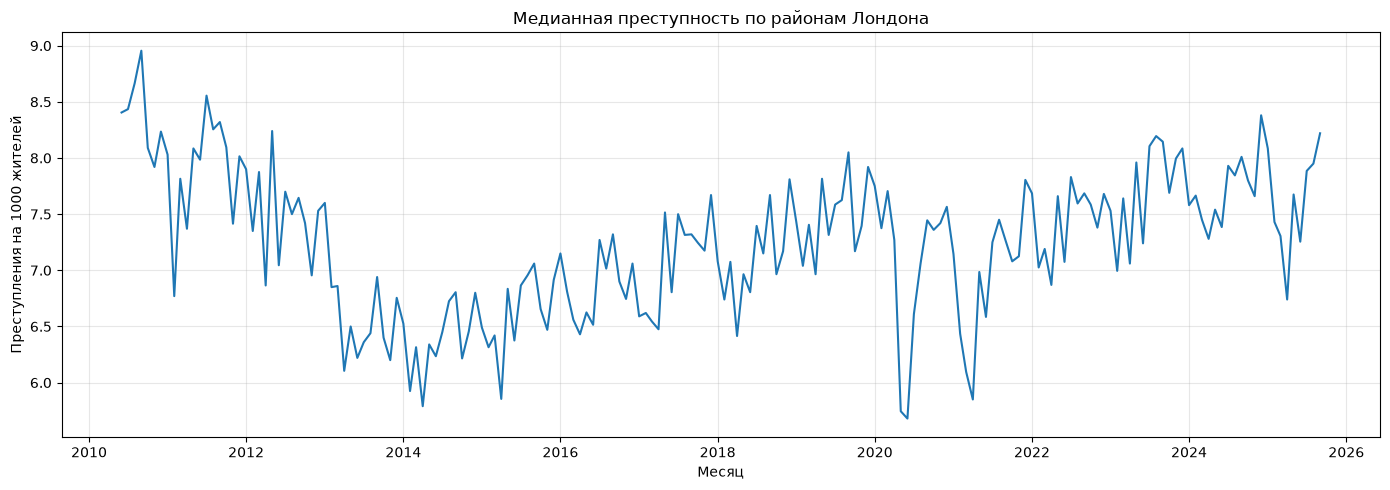

In [50]:
df["month"] = pd.to_datetime(df["month"])

crime_by_month = df.groupby("month")["crime_per_1000_lag2"].median().sort_index()

plt.figure(figsize=(14, 5))
plt.plot(crime_by_month.index, crime_by_month.values)

plt.title("Медианная преступность по районам Лондона")
plt.xlabel("Месяц")
plt.ylabel("Преступления на 1000 жителей")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Видно, что где-то с конца 2013 года общий тренд преступности на 1000 человек растёт по всем районам. Интересны также 2 резких спада с относительно быстрым восстановлением тренда в период с 2020 по 2022, очевидно связанные с ковидом.

Из этого с определенной долей осторожности можно сделать вывод, что мы можем заполнить `crime_per_1000_lag2` для `City of London` медианой по другим районам, так как общий тренд для всех районов - это рост преступности. Заполним:

In [51]:
crime_median_by_month = df.groupby("month")["crime_per_1000_lag2"].transform("median")

mask = df["borough"].eq("City of London") & df["crime_per_1000_lag2"].isna()

df.loc[mask, "crime_per_1000_lag2"] = crime_median_by_month[mask]

df["crime_per_1000_lag2"].describe()

count    6072.000000
mean        8.023701
std         3.898655
min         3.600000
25%         5.950000
50%         7.200000
75%         8.910000
max        45.790000
Name: crime_per_1000_lag2, dtype: float64

#### Пропуски в `mean_pay_prev_year`

Посмотрим сколько пропусков по этому столбцу:

In [52]:
int(df["mean_pay_prev_year"].isna().sum())

353

Пропуски появились из-за пустых значений зарплаты в источнике [**NOMIS**](https://www.nomisweb.co.uk) - отсутствие одной годовой оценки даёт пропуски сразу во всех месяцах соответствующего года. 

Найдём районы и года с такими пропусками:

In [53]:
(
    df.loc[df["mean_pay_prev_year"].isna(), ["borough", "year"]]
    .drop_duplicates()
    .sort_values(["borough", "year"])
)

,borough,year
6,City of London,2010
237,City of London,2011
633,City of London,2012
1029,City of London,2013
1425,City of London,2014
1821,City of London,2015
2217,City of London,2016
3801,City of London,2020
4197,City of London,2021
4593,City of London,2022


Причины таких пропусков в источнике NOMIS непонятны, но так как это официальный источник [ONS](https://www.ons.gov.uk), то примем эти пропуски как особенности источника. 

Заполним пропуски в `mean_pay_prev_year` медианой остальных районов за тот же месяц.

In [54]:
pay_median = df.groupby("month")["mean_pay_prev_year"].transform("median")
df["mean_pay_prev_year"] = df["mean_pay_prev_year"].fillna(pay_median)

df["mean_pay_prev_year"].describe()

count     6072.000000
mean     40005.477520
std      10939.937484
min      23703.000000
25%      32403.000000
50%      37411.000000
75%      45076.000000
max      99538.000000
Name: mean_pay_prev_year, dtype: float64

### Анализ ошибочных значений

Для проверки ошибочных значений построим "ящики с усами" для каждого числового признака и таргетов:

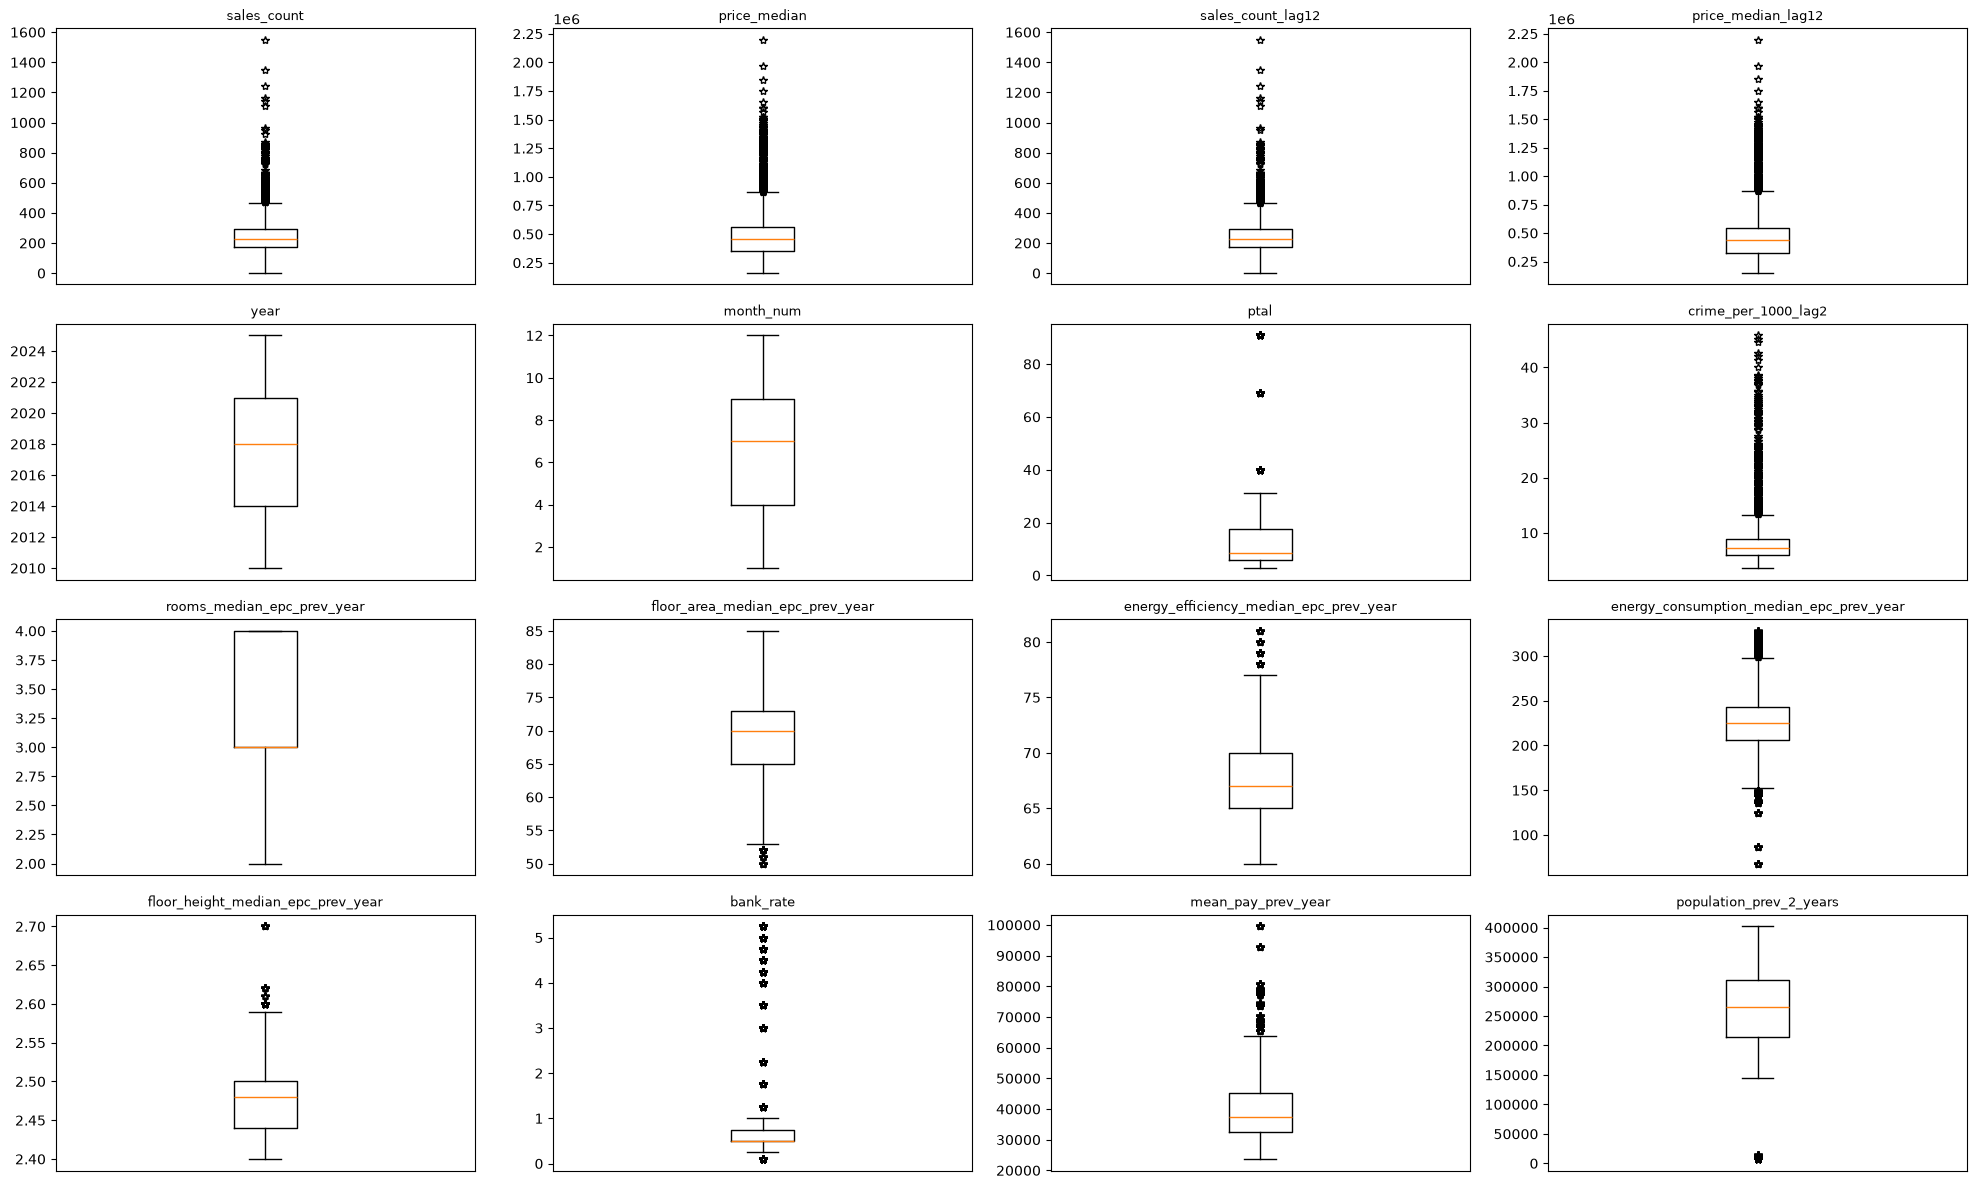

In [55]:
numeric = df.select_dtypes(include="number")

fig, axes = plt.subplots(4, 4, figsize=(20, 12))

for ax, col in zip(axes.flat, numeric.columns):
    ax.boxplot(numeric[col].dropna(), sym="*")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])

# Скрываем незанятые графики
for ax in axes.flat[len(numeric.columns) :]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

У части столбцов значения "выпадают" из своих ящиков с усами. Но это не означает, что там некорректные значения. Проанализируем их детальнее.

#### Анализ ошибок в `sales_count` и `sales_count_lag12`

Посмотрим в каких районах и в какие месяцы были наибольшие 20 продаж:

In [56]:
df.nlargest(20, "sales_count")[["month", "borough", "sales_count"]]

,month,borough,sales_count
4387,2021-06-01,Wandsworth,1548
4360,2021-06-01,Bromley,1351
4377,2021-06-01,Lambeth,1246
4385,2021-06-01,Tower Hamlets,1161
4357,2021-06-01,Barnet,1140
4363,2021-06-01,Croydon,1112
2308,2016-03-01,Wandsworth,962
4371,2021-06-01,Havering,951
5872,2025-03-01,Wandsworth,921
4288,2021-03-01,Wandsworth,871


Большинство крупнейших значений `sales_count` приходится на июнь 2021 года сразу в нескольких районах. Также встречаются пики в марте 2016 и марте 2025 года. Возможно, это общий рыночный тренд. Оснований удалять эти наблюдения только по boxplot пока никаких нет. Посмотрим на общее количество продаж по Лондону:

<Axes: title={'center': 'Общее количество продаж по Лондону'}, xlabel='Месяц', ylabel='Количество продаж'>

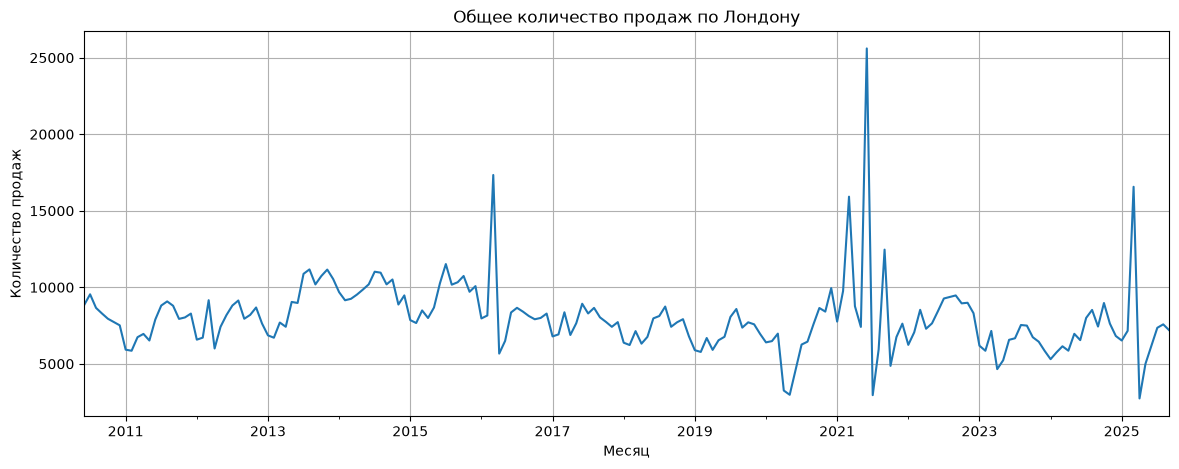

In [57]:
df.groupby("month")["sales_count"].sum().plot(
    figsize=(14, 5),
    title="Общее количество продаж по Лондону",
    xlabel="Месяц",
    ylabel="Количество продаж",
    grid=True,
)

Таким образом наибольшие значения `sales_count` совпадают со всплесками и последующим резкой просадкой продаж в 2016, 2021 и 2025 годах.

Поизучав источники подтверждаем, что данные всплески правдивы. Все три пика совпадают с изменениями налога на покупку недвижимости Stamp Duty Land Tax (SDLT). Покупатели торопились завершить сделки до повышения налога, поэтому после всплеска возникал спад.

* **Март 2016** - с 1 апреля вводилась доп надбавка 3% для второго жилья, включая покупку под сдачу. ONS связывает мартовский всплеск с этими изменениями: продажи в Англии и Уэльсе выросли на 71% относительно февраля. [Исследование ONS](https://www.ons.gov.uk/peoplepopulationandcommunity/housing/articles/theeffectofstampdutychangesonhousingmarketactivity/september2016).

* **Июнь 2021** - заканчивался основной этап налоговых каникул. С июля необлагаемый порог снижался с £500 000 до £250 000. HMRC прямо объясняет пик стремлением завершить сделки до сокращения льготы. [Комментарии HMRC](https://www.gov.uk/government/statistics/uk-stamp-tax-statistics/uk-stamp-tax-statistics-2023-to-2024-commentary).

* **Март 2025** - с 1 апреля снижались временно повышенные необлагаемые пороги SDLT. ONS отмечает, что сделки завершали заранее: по приведённым тогда оценкам HMRC, продажи по Великобритании выросли в марте на 61,6% относительно февраля, а в апреле упали на 63,5%. [Комментарии ONS](https://www.ons.gov.uk/economy/grossdomesticproductgdp/bulletins/gdpmonthlyestimateuk/april2025).

**Вывод**: явных ошибок в `sales_count` мы не обнаружили. Аномалии обусловлены рыночными факторами и действиями регулятора. Поэтому все данные `sales_count` сохраняем в неизменном состоянии. Аналогичный подход применяем к `sales_count_lag12`, потому что это количество продаж того же района со сдвигом на 12 месяцев.

#### Анализ ошибок в `price_median` и `price_median_lag12`

Посмотрим наибольшие 20 значений вместе с количеством продаж:

In [58]:
df.nlargest(20, "price_median")[["month", "borough", "price_median", "sales_count"]]

,month,borough,price_median,sales_count
4408,2021-07-01,Kensington and Chelsea,2195000.0,50
4441,2021-08-01,Kensington and Chelsea,1965310.0,124
3022,2018-01-01,Kensington and Chelsea,1850000.0,127
4705,2022-04-01,Kensington and Chelsea,1750000.0,159
4507,2021-10-01,Kensington and Chelsea,1650000.0,95
3055,2018-02-01,Kensington and Chelsea,1602500.0,86
2725,2017-04-01,Kensington and Chelsea,1600000.0,124
3121,2018-04-01,Kensington and Chelsea,1600000.0,119
4804,2022-07-01,Kensington and Chelsea,1565000.0,181
4639,2022-02-01,Kensington and Chelsea,1522500.0,128


Подавляющее число из них - это боро **Kensington and Chelsea**. На официальном сайте этого боро удалось найти документ [New Local Plan Review](https://www.rbkc.gov.uk/sites/default/files/media/documents/01_22-10-26_NLPR_Publication_policies_Oct_2022.pdf), где в пункте `3. Homes` в разделе `Keyfacts` прямо указано:
>The Office for National Statistics (ONS) reports that the median
price paid for homes at the end of September 2020 was c £1.3 million
in the Borough. This is also by far the highest anywhere in the country
if not globally.

Если посмотреть [предложения в этом боро на агрегаторах](https://search.savills.com/de/en/list/property-for-sale/england/kensington-and-chelsea-borough), то там очень много предложений квартир по огромным ценам.

**Вывод**: наибольшие значения `price_median` преимущественно сосредоточены в Kensington and Chelsea и повторяются в разные периоды. Оснований считать их ошибками по результатам этой проверки нет. Значения сохраняем без изменений. Аналогичный подход применяем к `price_median_lag12`, потому что это медианная цена продажи в районе со сдвигом на 12 месяцев.

#### Анализ ошибок в `ptal`

Посмотрим на верхние выпадающие значения индекса транспортной доступности:

In [59]:
(
    df.loc[df["ptal"] > 35, ["borough", "year", "ptal"]]
    .drop_duplicates()
    .sort_values(["ptal", "borough"], ascending=[False, True])
)

,borough,year,ptal
6,City of London,2010,90.80
237,City of London,2011,90.80
633,City of London,2012,90.80
1029,City of London,2013,90.80
1425,City of London,2014,90.80
1821,City of London,2015,90.80
2217,City of London,2016,90.80
2613,City of London,2017,90.80
3009,City of London,2018,90.80
3405,City of London,2019,90.80


Это два боро с наибольшей транспортной доступностью, что можно проверить по открытым источникам (в том числе и в самом [TfL](https://data.london.gov.uk/dataset/public-transport-accessibility-levels-24rz6)).

Тут важно также отметить, что транспортная доступность у TfL измеряется как доступность транспорта до центральной точки Лондона. Логично предположить, что деловой район в центре города `City of London` обладает наибольшим индексом транспортной доступности, а также один из ближайших к нему районов `Westminster`.

Интересно также, что введение [Elizabeth Line](https://en.wikipedia.org/wiki/Elizabeth_line) ухудшило общий индекс транспортной доступности по LSOA у `City of London`, а у `Westminster` оставило без изменений. Этот интересный факт выглядит странным, но его можно интерпретировать так, что введение аналога **Московского МЦД** увеличило приток людей в центральный деловой район `City of London`, при этом общественный транспорт внутри `City of London` под этот рост не был готов. Это лишь гипотеза, которая никак не влияет на EDA.

**Вывод:** наибольшие значения `ptal` в центральном деловом районе `City of London` и историческом центральном районе `Westminster`. Так как этот индекс измеряет транспортную доступность до центра - эти значения корректны и не являются ошибками. Значения сохраняем без изменений.

#### Анализ ошибок в `crime_per_1000_lag2`

Высокий показатель может здесь быть в боро с большим потоком посетителей, но относительно малым количеством населения в этом боро. Проверим это:

In [60]:
df.nlargest(20, "crime_per_1000_lag2")[
    ["month", "borough", "crime_per_1000_lag2", "population_prev_2_years"]
]

,month,borough,crime_per_1000_lag2,population_prev_2_years
5444,2024-02-01,Westminster,45.79,213009
5411,2024-01-01,Westminster,45.20,213009
5840,2025-02-01,Westminster,44.66,216343
5807,2025-01-01,Westminster,42.59,216343
5048,2023-02-01,Westminster,42.11,205759
5378,2023-12-01,Westminster,41.43,205759
5015,2023-01-01,Westminster,40.16,205759
5774,2024-12-01,Westminster,38.64,213009
5510,2024-04-01,Westminster,38.42,213009
5279,2023-09-01,Westminster,38.00,205759


Все 20 наибольших значений `crime_per_1000_lag2` относятся к Westminster, что говорит об устойчивой особенности района.

**Гипотеза:** это исторический центральный район, где сосредоточены основные достопримечательности Лондона. Большой туристический поток в этом районе, а также [рост количества уличных краж](https://www.onlondon.co.uk/londons-recent-rises-in-crimes-of-theft-some-three-year-patterns-and-trends/) в нём объясняют данный выброс. 

**Вывод:** наибольшие значения преступности на 1000 человек наблюдаются в районе `Westminster`. Это подтверждается сообщениями из СМИ. Считаем эти значения корректными и сохраняем без изменений.

#### Анализ ошибок в `floor_area_median_epc_prev_year`

Здесь медиана около 70 (м²), средние 50% значений - примерно 65 - 73. Несколько нижних точек находятся около 50–52 м² и сами по себе такие площади вполне правдоподобны.

Важно отметить, что это медианные площади по сертификатам EPC района за предыдущий год, а не площади отдельных объектов. Посмотрим, каким районам и годам соответствуют минимумы:

In [61]:
df[["borough", "year", "floor_area_median_epc_prev_year"]].drop_duplicates().nsmallest(
    20, "floor_area_median_epc_prev_year"
)

,borough,year,floor_area_median_epc_prev_year
5385,City of London,2024,50.0
4989,City of London,2023,51.0
1425,City of London,2014,52.0
3009,City of London,2018,52.0
1821,City of London,2015,53.0
5781,City of London,2025,53.0
237,City of London,2011,54.0
3801,City of London,2020,54.0
6,City of London,2010,55.0
633,City of London,2012,56.0


**Вывод:** минимальные медианные площади преимущественно наблюдаются в `City of London`. Значения 50–60 правдоподобны; явных признаков ошибок не видно. Значения сохраняем без изменений.

#### Анализ ошибок в `energy_efficiency_median_epc_prev_year`

Здесь медиана около 67 баллов, средние 50% значений - 65 - 70. Верхние точки около 78–81 балла означают более высокую энергоэффективность и сами по себе не выглядят ошибочными.

Посмотрим, каким районам и годам они соответствуют:

In [62]:
df[
    ["borough", "year", "energy_efficiency_median_epc_prev_year"]
].drop_duplicates().nlargest(20, "energy_efficiency_median_epc_prev_year")

,borough,year,energy_efficiency_median_epc_prev_year
3405,City of London,2019,81.0
1821,City of London,2015,80.0
2636,Tower Hamlets,2017,79.0
4616,Tower Hamlets,2022,79.0
5781,City of London,2025,79.0
3824,Tower Hamlets,2020,78.0
4220,Tower Hamlets,2021,78.0
5804,Tower Hamlets,2025,78.0
3009,City of London,2018,77.0
5012,Tower Hamlets,2023,77.0


**Вывод:** высокие медианные баллы энергоэффективности преимущественно относятся к `City of London` и `Tower Hamlets` и повторяются в разные годы. Значения выглядят правдоподобными. Явных признаков ошибок не видим. Данные сохраняем без изменений.

#### Анализ ошибок в `energy_consumption_median_epc_prev_year`

Медиана здесь около 225 (кВт*ч/м²) в год, средние 50% значений - примерно 205 - 245. Есть верхние выбросы до 330 и нижние - около 68 - 150.

Это расчётное энергопотребление по EPC, а не фактические показания счётчиков. Низкие и высокие значения сами по себе ещё не означают ошибку.

Посмотрим оба края, исключив повторения по месяцам:

In [63]:
annual = df[
    ["borough", "year", "energy_consumption_median_epc_prev_year"]
].drop_duplicates()

display(annual.nsmallest(10, "energy_consumption_median_epc_prev_year"))
display(annual.nlargest(10, "energy_consumption_median_epc_prev_year"))

,borough,year,energy_consumption_median_epc_prev_year
3405,City of London,2019,68.0
1821,City of London,2015,86.0
2636,Tower Hamlets,2017,125.0
4616,Tower Hamlets,2022,136.0
5804,Tower Hamlets,2025,137.5
3824,Tower Hamlets,2020,143.0
4220,Tower Hamlets,2021,143.0
5408,Tower Hamlets,2024,147.0
5012,Tower Hamlets,2023,149.0
3009,City of London,2018,152.0


,borough,year,energy_consumption_median_epc_prev_year
9,Enfield,2010,328.0
28,Sutton,2010,327.0
259,Sutton,2011,324.0
30,Waltham Forest,2010,323.0
13,Haringey,2010,321.0
251,Kingston upon Thames,2011,321.0
261,Waltham Forest,2011,320.0
20,Kingston upon Thames,2010,319.0
233,Bexley,2011,318.0
26,Richmond upon Thames,2010,316.0


**Вывод:** низкие значения энергопотребления `energy_consumption_median_epc_prev_year` согласуются с высокими баллами энергоэффективности `energy_efficiency_median_epc_prev_year` в тех же районах и годах. Явных признаков ошибок не видим. Значения сохраняем без изменений.

#### Анализ ошибок в `floor_height_median_epc_prev_year`

Медиана здесь в районе 2.48 (м), средние 50% значений - 2.44 - 2.50. Верхние точки достигают 2.70. Такая высота потолков не является чем-то ошибочным.

Посмотрим подробнее:

In [64]:
df[["borough", "year", "floor_height_median_epc_prev_year"]].drop_duplicates().nlargest(
    10, "floor_height_median_epc_prev_year"
)

,borough,year,floor_height_median_epc_prev_year
1425,City of London,2014,2.70
1821,City of London,2015,2.62
19,Kensington and Chelsea,2010,2.61
12,Hammersmith and Fulham,2010,2.60
13,Haringey,2010,2.60
243,Hammersmith and Fulham,2011,2.60
250,Kensington and Chelsea,2011,2.60
646,Kensington and Chelsea,2012,2.60
1035,Hammersmith and Fulham,2013,2.60
1042,Kensington and Chelsea,2013,2.60


**Вывод:** верхние значения медианной высоты помещений района находятся в правдоподобном диапазоне. Явных признаков ошибок по результатам проверки не обнаружено. Значения сохраняем без изменений.

#### Анализ ошибок в `bank_rate`

Сразу отметим, что ставка Банка Англии одинакова для всех районов в одном месяце. Посмотрим на изменение ставки:

<Axes: title={'center': 'Ставка Банка Англии на начало месяца'}, xlabel='Месяц', ylabel='Ставка, %'>

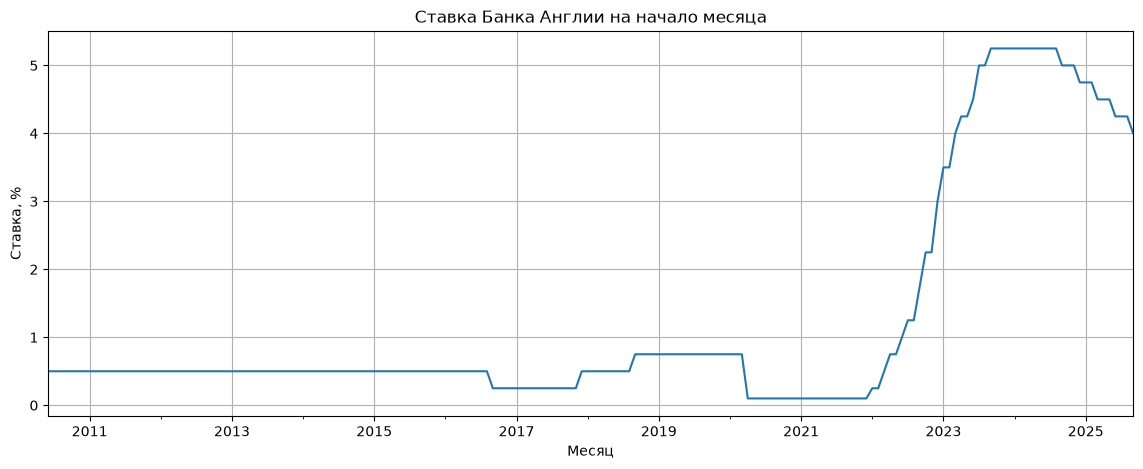

In [65]:
df.groupby("month")["bank_rate"].first().plot(
    figsize=(14, 5),
    title="Ставка Банка Англии на начало месяца",
    xlabel="Месяц",
    ylabel="Ставка, %",
    grid=True,
)

**Гипотеза:** резкий скачок ставки Банка Англии связан с пост-ковидными процессами в экономике.

**Вывод:** динамика изменений ставки Банка Англии соответствует [открытым данным](https://www.bankofengland.co.uk/boeapps/database/Bank-Rate.asp). Причины её резкого роста не являются темой данного анализа. Ошибок не наблюдаем. Значения сохраняем без изменений.

#### Анализ ошибок в `mean_pay_prev_year`

Это средняя годовая зарплата до вычета налогов по району за предыдущий год. Высокие значения могут зависеть от небольшой группы высокооплачиваемых работников. Сами по себе выпавшие значения не выглядят ошибочными. Посмотрим наибольшие значения:

In [66]:
df[["borough", "year", "mean_pay_prev_year"]].drop_duplicates().nlargest(
    20, "mean_pay_prev_year"
)

,borough,year,mean_pay_prev_year
1834,Kensington and Chelsea,2015,99538.0
3814,Kensington and Chelsea,2020,92675.0
263,Westminster,2011,80634.0
2230,Kensington and Chelsea,2016,78970.0
659,Westminster,2012,78794.0
3035,Westminster,2018,78386.0
5801,Richmond upon Thames,2025,77873.0
3431,Westminster,2019,77504.0
5781,City of London,2025,77069.0
32,Westminster,2010,74680.0


**Вывод:** явных ошибок в `mean_pay_prev_year` мы не обнаружили. Высокие значения присутствуют преимущественно в `Kensington and Chelsea` и `Westminster` и могут быть обсуловлены небольшой группой высокооплачиваемых работников. Значения сохраняем без изменений.

#### Анализ ошибок в `population_prev_2_years`

Медиана - в районе 265 тысяч жителей, средние 50% значений - примерно 215 – 310. Нижние точки - районы с населением менее 20 тысяч. Скорее всего - это деловой район в центре `City of London`. Посмотрим:

In [67]:
df[["borough", "year", "population_prev_2_years"]].drop_duplicates().nsmallest(
    20, "population_prev_2_years"
)

,borough,year,population_prev_2_years
633,City of London,2012,7338
1029,City of London,2013,7412
6,City of London,2010,7429
237,City of London,2011,7472
1425,City of London,2014,7514
1821,City of London,2015,7537
2217,City of London,2016,7567
2613,City of London,2017,7668
3009,City of London,2018,7737
3405,City of London,2019,7877


**Вывод:** низкие значения населения относятся к деловому району в центре - `City of London`. ONS при этом отмечает значительные миграционные изменения и повышенную неопределённость оценок для этого района (см. раздел ["Quality indicators" в методологии ONS](https://www.ons.gov.uk/peoplepopulationandcommunity/populationandmigration/populationestimates/methodologies/populationestimatesforenglandandwalesqualityandmethodsguide)). Рост составляет порядка 20.7% и связывать его с конкретным строительством нового жилья оснований не видим. Значения сохраняем как оценки официального источника ONS.

### Анализ типов столбцов датафрейма

In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6072 entries, 0 to 6071
Data columns (total 19 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   month                                    6072 non-null   datetime64[us]
 1   borough                                  6072 non-null   str           
 2   borough_code                             6072 non-null   str           
 3   sales_count                              6072 non-null   int64         
 4   price_median                             6072 non-null   float64       
 5   sales_count_lag12                        6072 non-null   int64         
 6   price_median_lag12                       6072 non-null   float64       
 7   year                                     6072 non-null   int64         
 8   month_num                                6072 non-null   int64         
 9   ptal                                     6072 non-nu

Сделаем столбец `month_num` **категориальным**, так как число месяцев в Григорианском календаре всегда равно 12:

In [69]:
df["month_num"] = df["month_num"].astype("category")
df["month_num"].info()

<class 'pandas.Series'>
RangeIndex: 6072 entries, 0 to 6071
Series name: month_num
Non-Null Count  Dtype   
--------------  -----   
6072 non-null   category
dtypes: category(1)
memory usage: 6.2 KB


Типы остальных столбцов мы оставляем без изменений. 

На данном этапе также заметили, что `borough_code` и `borough` дублируют себя и нет необходимости хранить оба. Оставим только `borough`:

In [70]:
df = df.drop(columns=["borough_code"])

### Масштабирование числовых признаков

In [71]:
# делаем копию для масштабирования
# чтобы на этапе обучения и оценки качества моделей можно было при необходимости сравнить
df_scaled = df.copy()

# Выбираем числовые признаки без таргетов и номера месяца
numeric_features = (
    df.drop(columns=["sales_count", "price_median", "month_num"])
    .select_dtypes(include="number")
    .columns
)

scaler = StandardScaler()
df_scaled[numeric_features] = scaler.fit_transform(df[numeric_features])

df_scaled.head()

,month,borough,sales_count,price_median,sales_count_lag12,price_median_lag12,year,month_num,ptal,crime_per_1000_lag2,rooms_median_epc_prev_year,floor_area_median_epc_prev_year,energy_efficiency_median_epc_prev_year,energy_consumption_median_epc_prev_year,floor_height_median_epc_prev_year,bank_rate,mean_pay_prev_year,population_prev_2_years
0,2010-06-01,Barking and Dagenham,146,170000.0,-1.369307,-1.461628,-1.707203,6,-0.563997,0.363309,-0.637001,-0.594546,-0.452151,1.949806,-1.389398,-0.460942,-1.312774,-1.173626
1,2010-06-01,Barnet,404,327500.0,-0.240380,-0.916210,-1.707203,6,-0.566618,-0.531946,-0.637001,-0.072908,-1.008250,2.391389,-0.339099,-0.460942,-0.537477,1.071794
2,2010-06-01,Bexley,208,212500.0,-0.595948,-1.266014,-1.707203,6,-0.631486,-0.732031,-0.637001,-0.594546,-0.730201,2.280993,-1.599457,-0.460942,-0.957258,-0.443824
3,2010-06-01,Brent,221,260000.0,-1.227080,-0.897800,-1.707203,6,-0.325495,0.052920,-0.637001,-0.942304,-0.730201,2.198196,0.711201,-0.460942,-1.179855,0.421288
4,2010-06-01,Bromley,442,283250.0,0.515201,-1.040483,-1.707203,6,-0.694388,-0.531946,-0.637001,0.622609,-1.286300,2.308592,-0.969278,-0.460942,-0.041546,0.610700


### Анализ корреляции признаков с таргетами

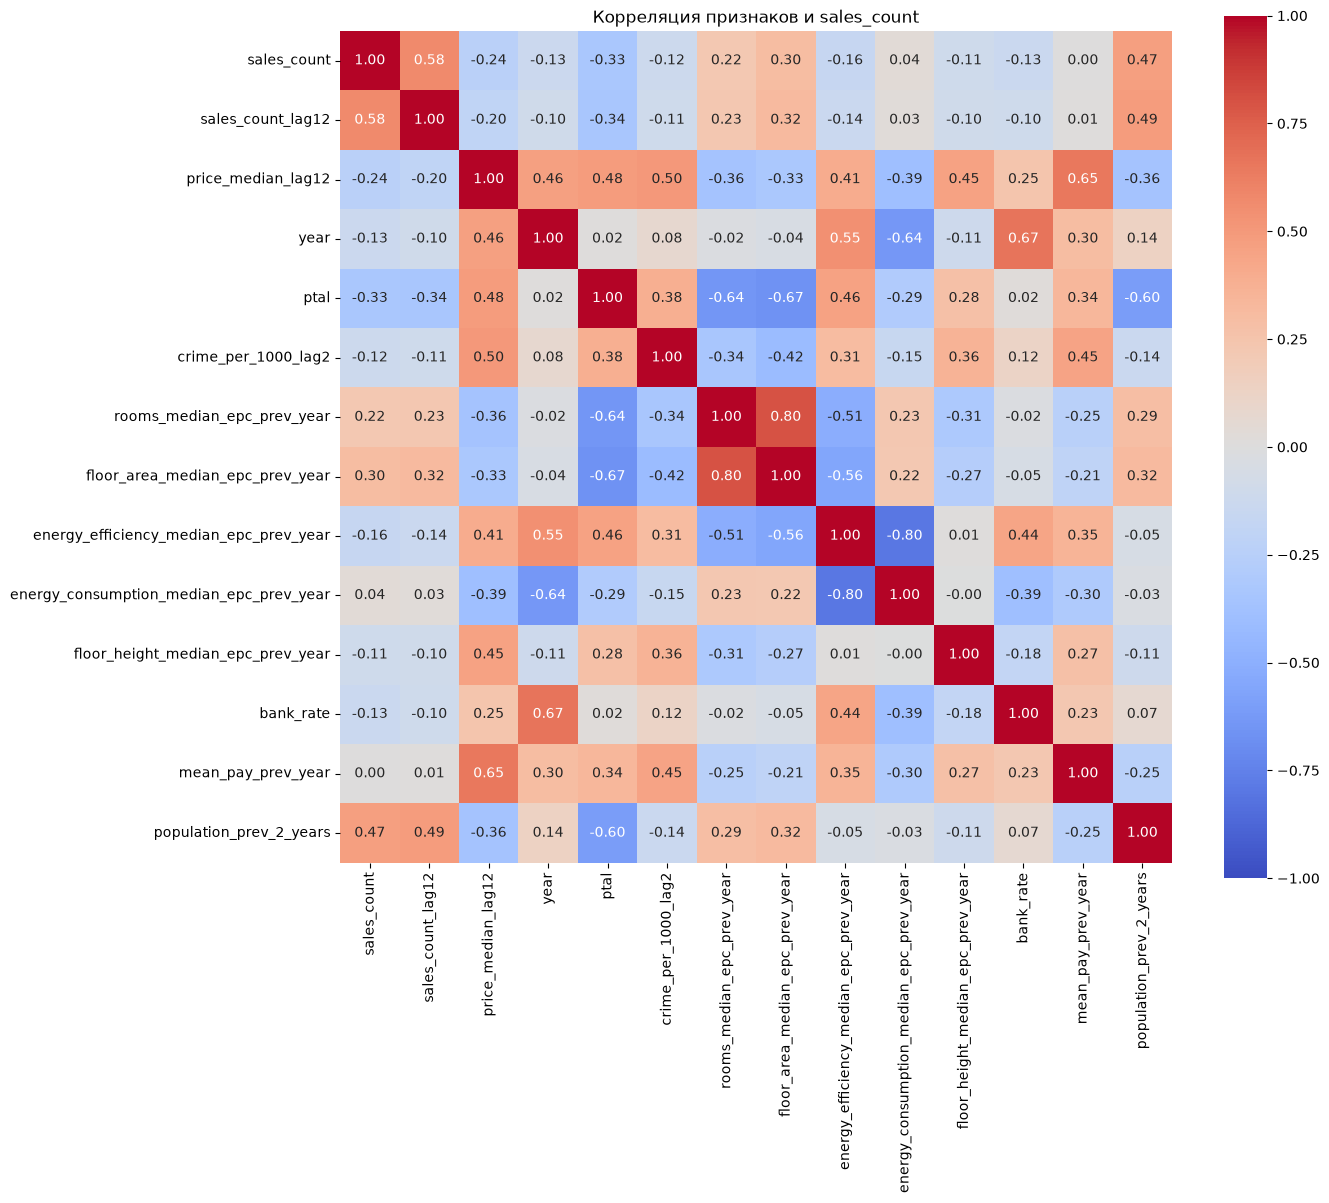

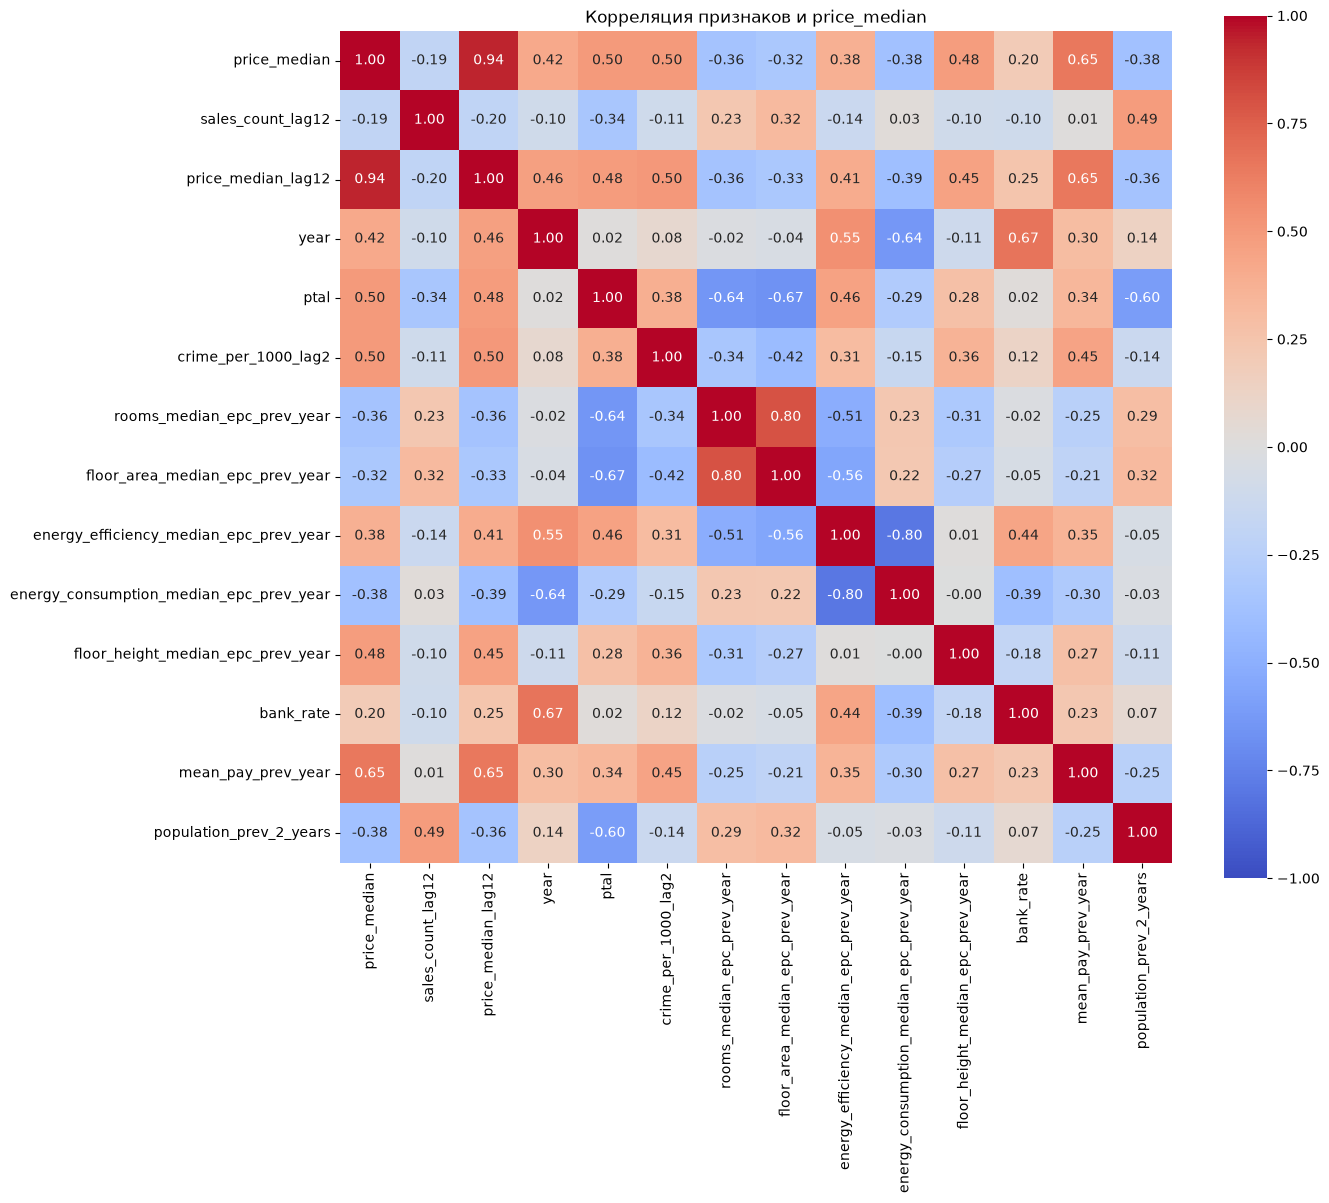

In [72]:
numeric = df.select_dtypes(include="number")

for target in ["sales_count", "price_median"]:
    other_target = "price_median" if target == "sales_count" else "sales_count"
    corr = numeric.drop(columns=[other_target]).corr()

    plt.figure(figsize=(14, 12))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
    )

    plt.title(f"Корреляция признаков и {target}")
    plt.tight_layout()
    plt.show()

**Выводы**

Для `sales_count`:
* Самая заметная связь с продажами год назад `sales_count_lag12`: 0.58
* Население `population_prev_2_years` связано с продажами положительно: 0.47. В более населённых районах обычно больше сделок.
* Связь с индексом транспортной доступности `ptal` отрицательная: −0.33, а с площадью `floor_area_median_epc_prev_year` положительная: 0.30. Это интересно и может отражать различия между боро, а не непосредственное влияние транспортной доступности или медианной площади объектов в районе.
* Средняя зарплата в районе имеет корреляцию около 0. Это кажется логичным, так как покупки в районах делают обычно люди из других районов. **Это стоит иметь в виду и для модели по `sales_count` есть смысл посмотреть на качество модели с убранным признаком `mean_pay_prev_year`**


Для `price_median`:
* Очень сильная связь с `price_median_lag12` ценой год назад: 0.94. **Обязательно стоит сравнить полученную модель с прогнозом "цена равна прошлогодней" aka "завтра будет также как вчера"**.
* Заметные положительные связи с зарплатой `mean_pay_prev_year` (0.65), `ptal` (0.50), преступностью `crime_per_1000_lag2` (0.50) и высотой помещений `floor_height_median_epc_prev_year` (0.48).
* Положительная связь цены с преступностью `crime_per_1000_lag2` - это интересно, но не означает, что преступность повышает цены. Дорогие центральные районы могут одновременно иметь высокую транспортную доступность и много зарегистрированных преступлений.
* Отрицательная связь с площадью `floor_area_median_epc_prev_year` (−0.32) тоже не означает, что большое жильё дешевле: сравниваются районные медианы, а не площадь и цена одного объекта.

Также важно, что между признаками есть сильные связи: 
* комнаты `rooms_median_epc_prev_year` и площадь `floor_area_median_epc_prev_year`: 0.80
* энергоэффективность `energy_efficiency_median_epc_prev_year` и энергопотребление `energy_consumption_median_epc_prev_year`: −0.80


Поэтому на данном этапе мы принимаем решение удалить признаки `rooms_median_epc_prev_year` и `energy_consumption_median_epc_prev_year`:

In [73]:
columns_to_drop = [
    "rooms_median_epc_prev_year",
    "energy_consumption_median_epc_prev_year",
]

df = df.drop(columns=columns_to_drop)
df_scaled = df_scaled.drop(columns=columns_to_drop)

## Выводы

1. В `crime_per_1000_lag2` обнаружили `184` пропуска (`3.0%`), а в `mean_pay_prev_year` - `353` (`5.8%`). Заполнили их медианой по районам с известными значениями за тот же месяц.

2. Явных ошибочных значений при проведённом анализе не обнаружили. Крайние значения проанализировали отдельно и подтвердили их правдоподобнось.

3. Числовые признаки имеют разные масштабы, поэтому создали масштабированную копию `df_scaled`.

4. `month_num` перевели в категориальный тип, поскольку он описывает сезонность продаж по 12-ти календарным месяцам. `month` сохранили для графиков и разделения данных по времени (возможно, ещё потребуется для анализа временных рядов). **В обучении моделей использовать `month` его НЕ нужно - это не признак**.

5. Ярко выраженная корреляция с таргетами наблюдается у их прошлогодних значений: `0.58` для количества продаж и `0.94` для медианной цены. Для продаж также выделяется население района `population_prev_2_years`, для цены — средняя зарплата `mean_pay_prev_year`.

6. Обнаружили сильные связи между комнатами и площадью, а также между энергоэффективностью и энергопотреблением. Для упрощения модели исключили признаки `rooms_median_epc_prev_year` и `energy_consumption_median_epc_prev_year`. Влияние этого решения можно дополнительно проверить на этапе обучения моделей.

7. Оба таргета имеют линейную корреляцию с несколькими признаками. Применение методов машинного обучения для прогнозирования продаж и медианной цены обосновано.

Итоговые датафреймы:

In [74]:
display(df.info())
display(df_scaled.info())

<class 'pandas.DataFrame'>
RangeIndex: 6072 entries, 0 to 6071
Data columns (total 16 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   month                                   6072 non-null   datetime64[us]
 1   borough                                 6072 non-null   str           
 2   sales_count                             6072 non-null   int64         
 3   price_median                            6072 non-null   float64       
 4   sales_count_lag12                       6072 non-null   int64         
 5   price_median_lag12                      6072 non-null   float64       
 6   year                                    6072 non-null   int64         
 7   month_num                               6072 non-null   category      
 8   ptal                                    6072 non-null   float64       
 9   crime_per_1000_lag2                     6072 non-null   float64

None

<class 'pandas.DataFrame'>
RangeIndex: 6072 entries, 0 to 6071
Data columns (total 16 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   month                                   6072 non-null   datetime64[us]
 1   borough                                 6072 non-null   str           
 2   sales_count                             6072 non-null   int64         
 3   price_median                            6072 non-null   float64       
 4   sales_count_lag12                       6072 non-null   float64       
 5   price_median_lag12                      6072 non-null   float64       
 6   year                                    6072 non-null   float64       
 7   month_num                               6072 non-null   category      
 8   ptal                                    6072 non-null   float64       
 9   crime_per_1000_lag2                     6072 non-null   float64

None

Сохраним итоговые данные:

In [75]:
df.to_csv("../dataset/data/borough-month-eda.csv", index=False)
df_scaled.to_csv("../dataset/data/borough-month-eda-scaled.csv", index=False)

## Appendix. Временные ряды продаж и медианных цен по боро

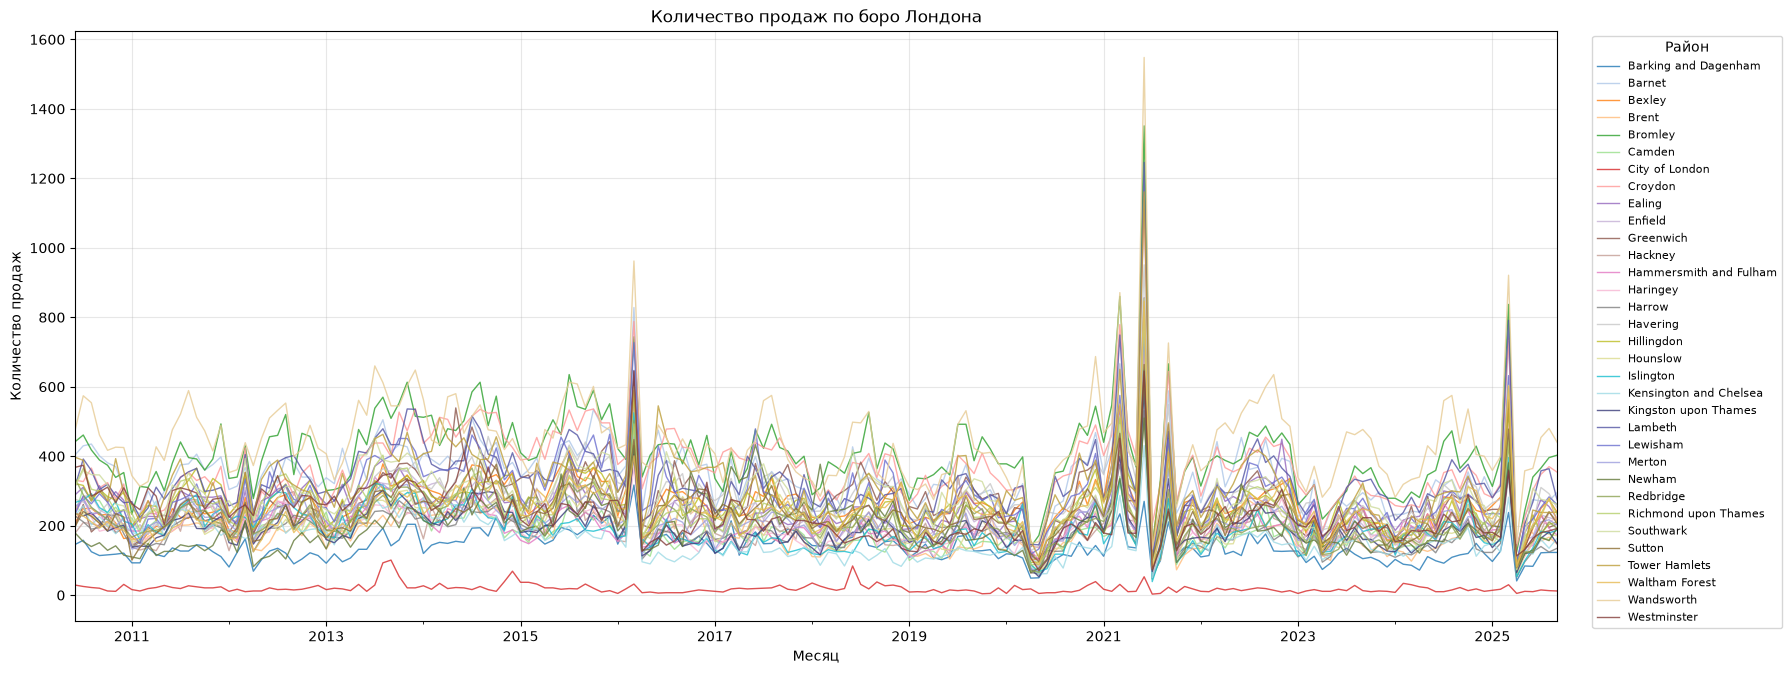

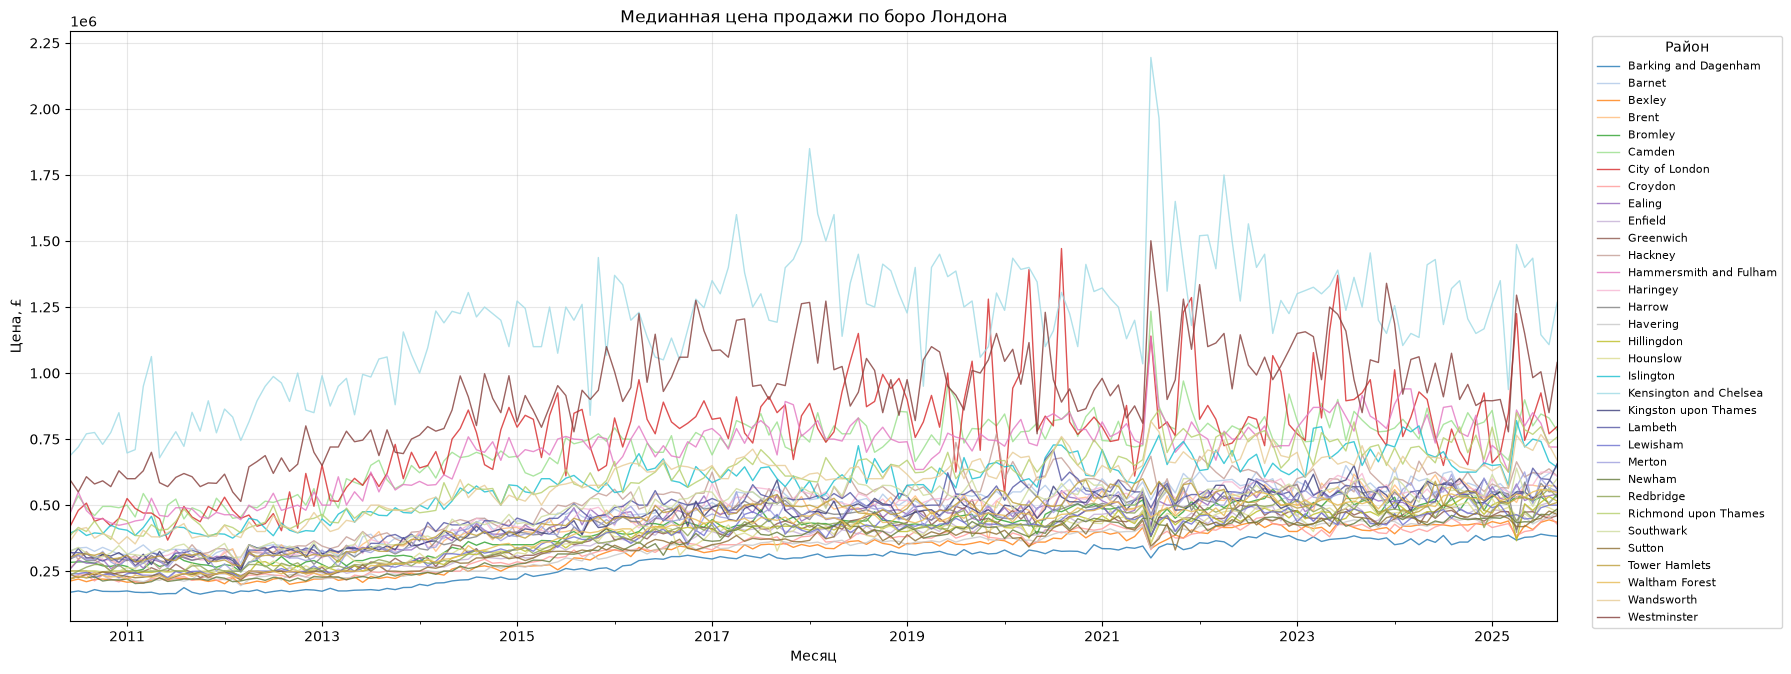

In [76]:
sales = df.pivot(index="month", columns="borough", values="sales_count")
prices = df.pivot(index="month", columns="borough", values="price_median")

sales.index = pd.to_datetime(sales.index)
prices.index = pd.to_datetime(prices.index)

colors = plt.cm.tab20.colors + plt.cm.tab20b.colors

for data, title, ylabel in [
    (sales, "Количество продаж по боро Лондона", "Количество продаж"),
    (prices, "Медианная цена продажи по боро Лондона", "Цена, £"),
]:
    ax = data.sort_index().plot(
        figsize=(18, 7), color=colors[: len(data.columns)], linewidth=1, alpha=0.8
    )

    ax.set_title(title)
    ax.set_xlabel("Месяц")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)

    ax.legend(title="Район", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

    plt.tight_layout()
    plt.show()